,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


Shape: (20640, 9)
MAE: 0.5332001304956561
MSE: 0.5558915986952438
RMSE: 0.745581383012776
R-squared: 0.5757877060324512


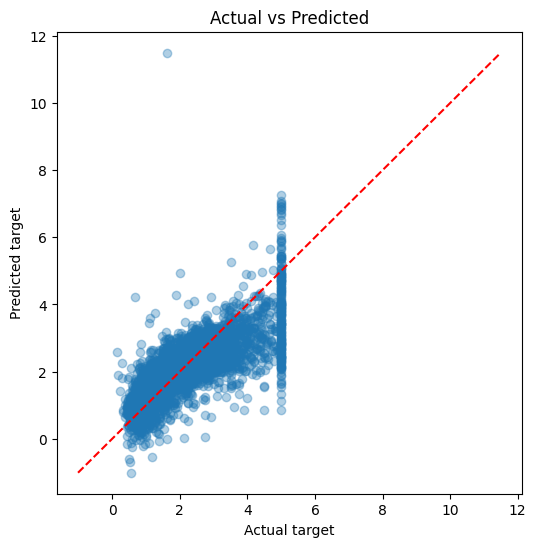

,Coefficient
Longitude,-0.433708
Latitude,-0.419792
AveRooms,-0.123323
AveOccup,-0.003526
Population,-0.000002
HouseAge,0.009724
MedInc,0.448675
AveBedrms,0.783145


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

housing = fetch_california_housing(as_frame=True)
df = housing.frame
display(df.head())
print("Shape:", df.shape)

X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
model = LinearRegression()
model.fit(X_train, y_train)
pred = model.predict(X_test)

mse = mean_squared_error(y_test, pred)
print("MAE:", mean_absolute_error(y_test, pred))
print("MSE:", mse)
print("RMSE:", np.sqrt(mse))
print("R-squared:", r2_score(y_test, pred))

plt.figure(figsize=(6,6))
plt.scatter(y_test, pred, alpha=0.35)
lo, hi = min(y_test.min(), pred.min()), max(y_test.max(), pred.max())
plt.plot([lo,hi], [lo,hi], "r--")
plt.xlabel("Actual target")
plt.ylabel("Predicted target")
plt.title("Actual vs Predicted")
plt.show()

display(pd.Series(model.coef_, index=X.columns).sort_values().to_frame("Coefficient"))